# Day 26 | Build a Chatbot Students Can Use

**KGP Talkie**

Turn prompts, streaming, and history into a small web app.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [2]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [3]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

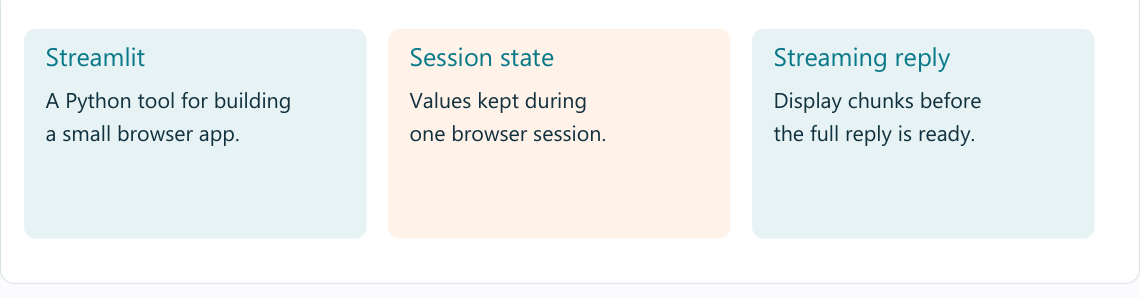

## Run the chat page

From the repository folder: `.venv\Scripts\python.exe -m streamlit run materials/day-26/app.py`. The app uses the same installed model and course environment.

The app stores a user turn and then an assistant turn. These roles must stay in order.

In [4]:
from langchain_core.messages import HumanMessage, AIMessage

These two local example turns show the shape of a history list.

In [5]:
turns = [HumanMessage(content="My name is Asha."), AIMessage(content="Hello, Asha.")]

In [6]:
[(turn.type, turn.content) for turn in turns]

[('human', 'My name is Asha.'), ('ai', 'Hello, Asha.')]

AppTest runs the real app script and lets us inspect the page widgets.

In [7]:
from streamlit.testing.v1 import AppTest

In [8]:
app = AppTest.from_file(str(BASE / "app.py"), default_timeout=30).run()  # Allow time for the app imports on the first run.

2026-10-09 13:12:29.736 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


The app must show a chat box without an exception before we try a message.

In [9]:
print("App errors:", len(app.exception))
print("Chat boxes:", len(app.chat_input))

App errors: 0
Chat boxes: 1


This submits a real fresh question to the local model through the app.

In [10]:
app.chat_input[0].set_value("Say hello in one short sentence.").run(timeout=180)

AppTest(
    _script_path='C:\\Users\\Acer\\Downloads\\80 Hour Genai Materials\\.ml-work\\oct09\\ready\\day-26\\app.py',
    default_timeout=3,
    _session_state={messages: [{'role': 'user', 'content': 'Say hello in one short sentence.'}, {'role': 'assistant', 'content': 'Hello!'}], $$STREAMLIT_INTERNAL_KEY_TESTING: {'$$ID-72d773c25d0d3cb6c36dfefb8e1b956d-None': False, '$$ID-6c1ec659a4d781b2c6b24f7e281e3154-None': 'Say hello in one short sentence.'}, $$STREAMLIT_INTERNAL_KEY_SCRIPT_RUN_WITHOUT_ERRORS: True, $$ID-6c1ec659a4d781b2c6b24f7e281e3154-None: None, $$ID-72d773c25d0d3cb6c36dfefb8e1b956d-None: False},
    session_state={'messages': [{'role': 'user', 'content': 'Say hello in one short sentence.'}, {'role': 'assistant', 'content': 'Hello!'}]},
    _registered_pages={
        7cf57d85bf208f6744806026d34e17f7: {'page_script_hash': '', 'page_name': '', 'icon': '', 'script_path': 'C:\\Users\\Acer\\Downloads\\80 Hour Genai Materials\\.ml-work\\oct09\\ready\\day-26\\app.py'}
    },
    

In [11]:
print("App errors:", len(app.exception))
print("Saved turns:", len(app.session_state["messages"]))

App errors: 0
Saved turns: 2


In [12]:
app.button[0].click().run()
print("After clear:", len(app.session_state["messages"]))

After clear: 0


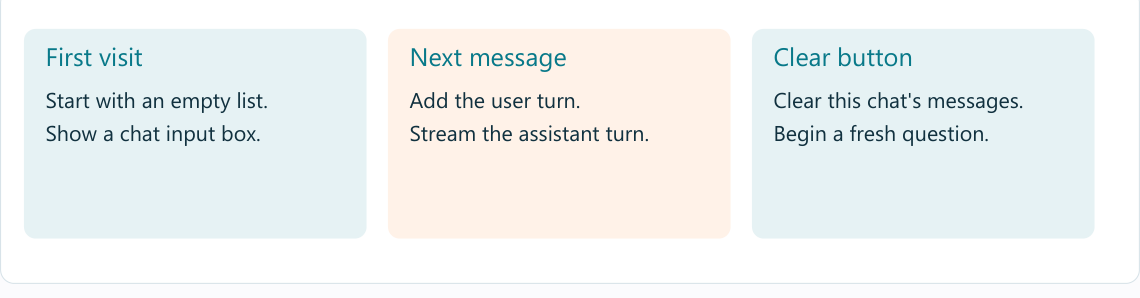

## Try a fresh input

Compare visible bubbles with the actual message list in the notebook exercise.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-chatbot).